# Training Pipeline — Diabetes Health Indicators (Dataset 6)

Training **9 classical ML models** on the preprocessed BRFSS 2015 diabetes dataset.

| Model | Dataset Used |
|---|---|
| Logistic Regression, KNN, SVM | One-Hot Encoded + Scaled |
| Decision Tree, Random Forest, XGBoost, AdaBoost, Gradient Boost, LGBM | Ordinal + Scaled |

**This notebook covers:** Training + Accuracy + Confusion Matrix for each model.  
Detailed evaluation metrics and comparison graphs will be added later.

In [1]:
%pip install matplotlib pandas numpy seaborn scikit-learn xgboost lightgbm

Note: you may need to restart the kernel to use updated packages.


## Import Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import time

# Classifiers
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)
from sklearn.svm import SVC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Metrics
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

warnings.filterwarnings('ignore')
sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 100

print("✓ All libraries imported successfully")

✓ All libraries imported successfully


## Load Preprocessed Datasets

- **Ordinal dataset** → tree-based models (Decision Tree, Random Forest, XGBoost, AdaBoost, Gradient Boost, LGBM)
- **Encoded dataset** → linear/distance-based models (Logistic Regression, KNN, SVM)

In [3]:
# ── Load ordinal (tree-based) datasets ──
train_ord = pd.read_csv('/kaggle/input/datasets/mosharafapurbo/cdc-diabetes-preprocessed-dataset/6_diabetes_ordinal_train.csv')
test_ord = pd.read_csv('/kaggle/input/datasets/mosharafapurbo/cdc-diabetes-preprocessed-dataset/6_diabetes_ordinal_test.csv')

LABEL = 'Diabetes_binary'

X_train_ord = train_ord.drop(columns=[LABEL])
Y_train_ord = train_ord[LABEL].astype(int)
X_test_ord = test_ord.drop(columns=[LABEL])
Y_test_ord = test_ord[LABEL].astype(int)

# ── Load encoded (linear/distance) datasets ──
train_enc = pd.read_csv('/kaggle/input/datasets/mosharafapurbo/cdc-diabetes-preprocessed-dataset/6_diabetes_encoded_train.csv')
test_enc = pd.read_csv('/kaggle/input/datasets/mosharafapurbo/cdc-diabetes-preprocessed-dataset/6_diabetes_encoded_test.csv')

X_train_enc = train_enc.drop(columns=[LABEL])
Y_train_enc = train_enc[LABEL].astype(int)
X_test_enc = test_enc.drop(columns=[LABEL])
Y_test_enc = test_enc[LABEL].astype(int)

print("Ordinal  → Train:", X_train_ord.shape, " Test:", X_test_ord.shape)
print("Encoded  → Train:", X_train_enc.shape, " Test:", X_test_enc.shape)
print(f"\nTrain class balance (ordinal): {Y_train_ord.value_counts().to_dict()}")
print(f"Train class balance (encoded): {Y_train_enc.value_counts().to_dict()}")

Ordinal  → Train: (49135, 21)  Test: (21059, 21)
Encoded  → Train: (49135, 49)  Test: (21059, 49)

Train class balance (ordinal): {0: 24629, 1: 24506}
Train class balance (encoded): {0: 24629, 1: 24506}


In [4]:
# ── Helper: Train, evaluate, and store results ──
results = {}  # Store all model results

def train_and_evaluate(model, model_name, X_train, X_test, Y_train, Y_test):
    """Train a model, print accuracy, show confusion matrix, store results."""
    start = time.time()
    model.fit(X_train, Y_train)
    train_time = time.time() - start
    
    Y_pred = model.predict(X_test)
    acc = accuracy_score(Y_test, Y_pred)
    cm = confusion_matrix(Y_test, Y_pred)
    
    # Store results for later comparison
    results[model_name] = {
        'model': model,
        'accuracy': acc,
        'confusion_matrix': cm,
        'predictions': Y_pred,
        'train_time': train_time
    }
    
    # Print results
    print(f"{'=' * 55}")
    print(f"  {model_name}")
    print(f"{'=' * 55}")
    print(f"  Accuracy:   {acc:.4f}  ({acc*100:.2f}%)")
    print(f"  Train Time: {train_time:.2f}s")
    print(f"{'=' * 55}\n")
    
    # Plot confusion matrix
    fig, ax = plt.subplots(1, 1, figsize=(6, 5))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Diabetes', 'Diabetes'])
    disp.plot(ax=ax, cmap='Blues', values_format='d')
    ax.set_title(f'{model_name}\nAccuracy: {acc*100:.2f}%', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    return acc

print("✓ Helper function defined")

✓ Helper function defined


---
## Linear / Distance-Based Models (One-Hot Encoded Dataset)

### 1. Logistic Regression

  Logistic Regression
  Accuracy:   0.8455  (84.55%)
  Train Time: 0.25s



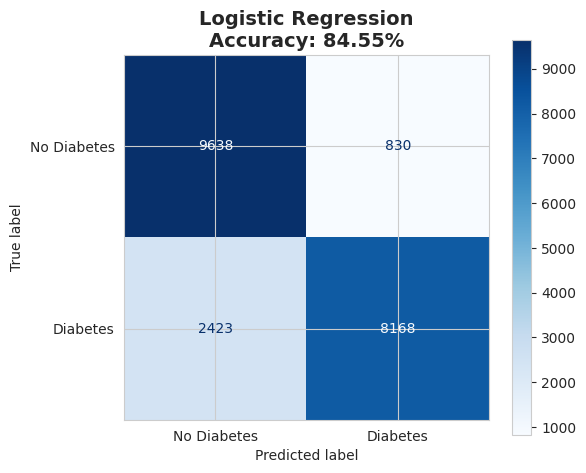

0.8455292274087088

In [5]:
# 1. Logistic Regression (Encoded dataset)
lr_model = LogisticRegression(max_iter=1000, random_state=42, solver='lbfgs')
train_and_evaluate(lr_model, "Logistic Regression", X_train_enc, X_test_enc, Y_train_enc, Y_test_enc)

### 2. K-Nearest Neighbors (KNN)

  KNN
  Accuracy:   0.7768  (77.68%)
  Train Time: 0.02s



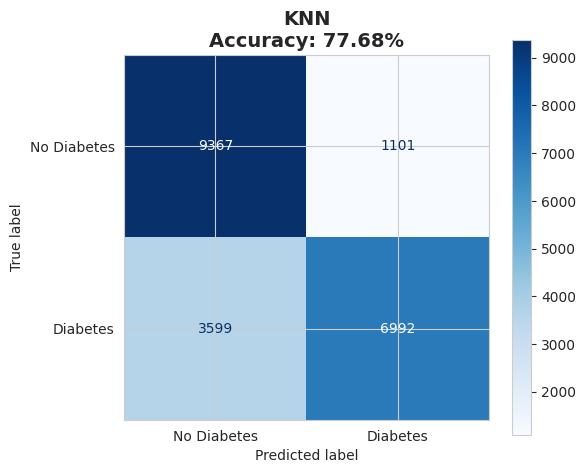

0.7768175127024075

In [6]:
# 2. KNN (Encoded dataset)
knn_model = KNeighborsClassifier(n_neighbors=5)
train_and_evaluate(knn_model, "KNN", X_train_enc, X_test_enc, Y_train_enc, Y_test_enc)

### 3. Support Vector Machine (SVM)

  SVM
  Accuracy:   0.8537  (85.37%)
  Train Time: 70.51s



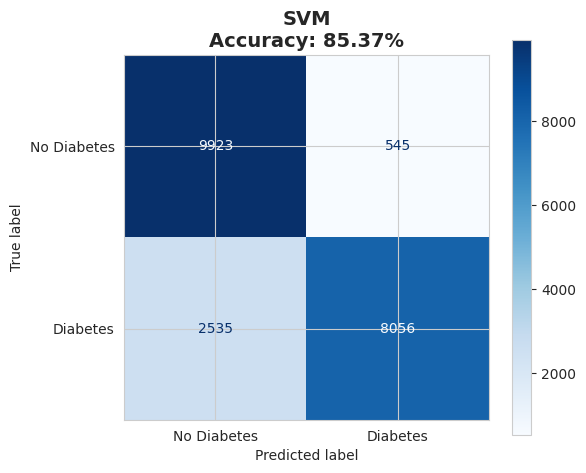

0.8537442423666841

In [7]:
# 3. SVM (Encoded dataset)
svm_model = SVC(kernel='rbf', random_state=42)
train_and_evaluate(svm_model, "SVM", X_train_enc, X_test_enc, Y_train_enc, Y_test_enc)

---
## Tree-Based Models (Ordinal Dataset)

### 4. Decision Tree

  Decision Tree
  Accuracy:   0.7662  (76.62%)
  Train Time: 0.18s



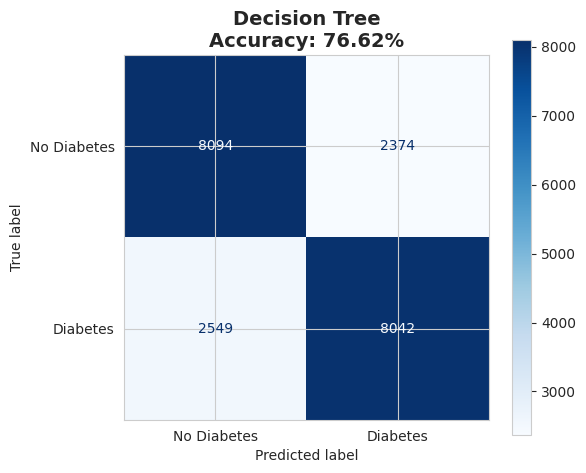

0.7662282159646707

In [8]:
# 4. Decision Tree (Ordinal dataset)
dt_model = DecisionTreeClassifier(random_state=42)
train_and_evaluate(dt_model, "Decision Tree", X_train_ord, X_test_ord, Y_train_ord, Y_test_ord)

### 5. Random Forest

  Random Forest
  Accuracy:   0.8245  (82.45%)
  Train Time: 1.71s



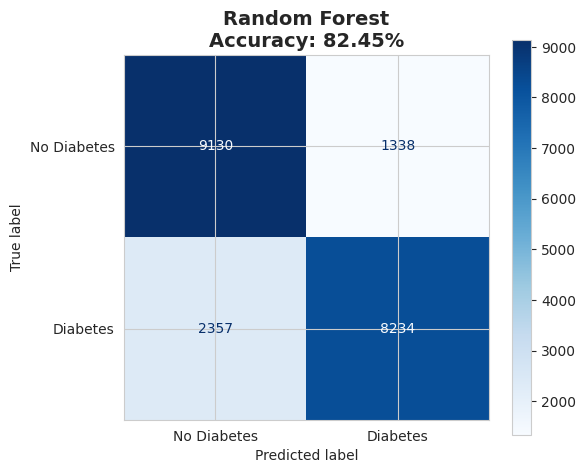

0.8245405764756161

In [9]:
# 5. Random Forest (Ordinal dataset)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
train_and_evaluate(rf_model, "Random Forest", X_train_ord, X_test_ord, Y_train_ord, Y_test_ord)

### 6. XGBoost

  XGBoost
  Accuracy:   0.8540  (85.40%)
  Train Time: 0.71s



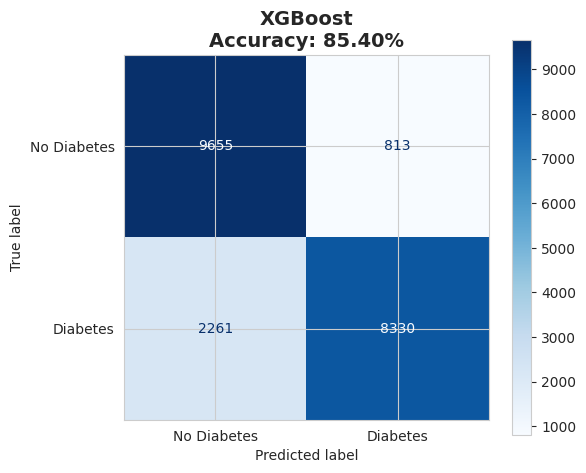

0.8540291561802554

In [10]:
# 6. XGBoost (Ordinal dataset)
xgb_model = XGBClassifier(
    n_estimators=100, 
    learning_rate=0.1, 
    max_depth=6,
    random_state=42,
    use_label_encoder=False, 
    eval_metric='logloss',
    verbosity=0
)
train_and_evaluate(xgb_model, "XGBoost", X_train_ord, X_test_ord, Y_train_ord, Y_test_ord)

### 7. AdaBoost Classifier

  AdaBoost
  Accuracy:   0.8228  (82.28%)
  Train Time: 1.66s



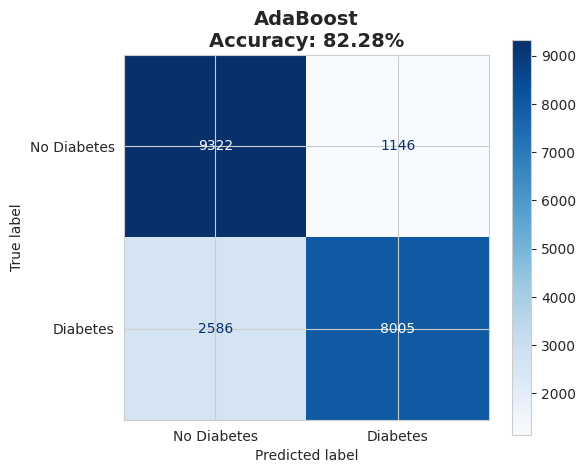

0.8227836079585925

In [11]:
# 7. AdaBoost (Ordinal dataset)
ada_model = AdaBoostClassifier(n_estimators=100, learning_rate=1.0, random_state=42)
train_and_evaluate(ada_model, "AdaBoost", X_train_ord, X_test_ord, Y_train_ord, Y_test_ord)

### 8. Gradient Boosting

  Gradient Boost
  Accuracy:   0.8464  (84.64%)
  Train Time: 3.68s



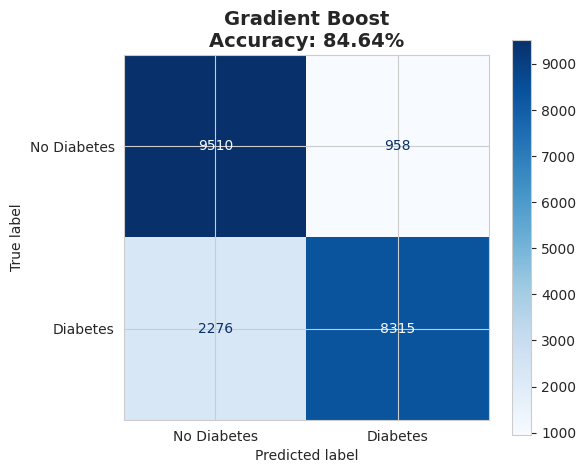

0.8464314544850183

In [12]:
# 8. Gradient Boosting (Ordinal dataset)
gb_model = GradientBoostingClassifier(
    n_estimators=100, 
    learning_rate=0.1, 
    max_depth=3, 
    random_state=42
)
train_and_evaluate(gb_model, "Gradient Boost", X_train_ord, X_test_ord, Y_train_ord, Y_test_ord)

### 9. LightGBM

  LGBM
  Accuracy:   0.8545  (85.45%)
  Train Time: 0.39s



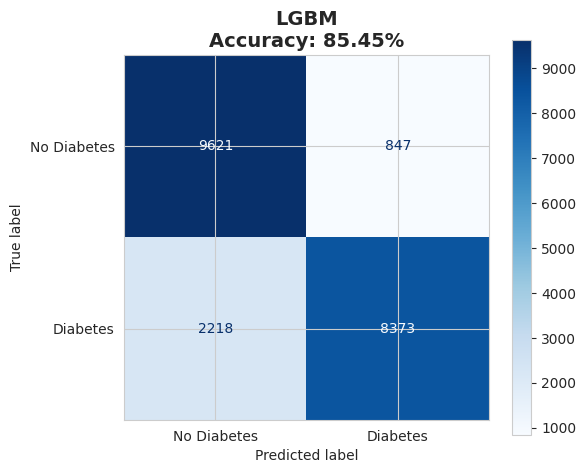

0.8544565269006126

In [13]:
# 9. LightGBM (Ordinal dataset)
lgbm_model = LGBMClassifier(
    n_estimators=100, 
    learning_rate=0.1, 
    max_depth=-1,
    random_state=42,
    verbose=-1
)
train_and_evaluate(lgbm_model, "LGBM", X_train_ord, X_test_ord, Y_train_ord, Y_test_ord)

---
## Model Comparison — Accuracy Summary

In [14]:
# ── Accuracy Comparison Table ──
comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Accuracy (%)': [r['accuracy'] * 100 for r in results.values()],
    'Train Time (s)': [r['train_time'] for r in results.values()]
}).sort_values('Accuracy (%)', ascending=False).reset_index(drop=True)

comparison_df.index += 1  # Rank starts from 1
comparison_df.index.name = 'Rank'

print("=" * 60)
print("  MODEL ACCURACY COMPARISON — Diabetes Prediction")
print("=" * 60)
print(comparison_df.to_string())
print("=" * 60)
print(f"\n🏆 Best Model: {comparison_df.iloc[0]['Model']} ({comparison_df.iloc[0]['Accuracy (%)']:.2f}%)")
comparison_df

  MODEL ACCURACY COMPARISON — Diabetes Prediction
                    Model  Accuracy (%)  Train Time (s)
Rank                                                   
1                    LGBM     85.445653        0.394701
2                 XGBoost     85.402916        0.713704
3                     SVM     85.374424       70.512143
4          Gradient Boost     84.643145        3.677641
5     Logistic Regression     84.552923        0.254704
6           Random Forest     82.454058        1.705463
7                AdaBoost     82.278361        1.656096
8                     KNN     77.681751        0.017631
9           Decision Tree     76.622822        0.184455

🏆 Best Model: LGBM (85.45%)


,Model,Accuracy (%),Train Time (s)
Rank,,,
1,LGBM,85.445653,0.394701
2,XGBoost,85.402916,0.713704
3,SVM,85.374424,70.512143
4,Gradient Boost,84.643145,3.677641
5,Logistic Regression,84.552923,0.254704
6,Random Forest,82.454058,1.705463
7,AdaBoost,82.278361,1.656096
8,KNN,77.681751,0.017631
9,Decision Tree,76.622822,0.184455


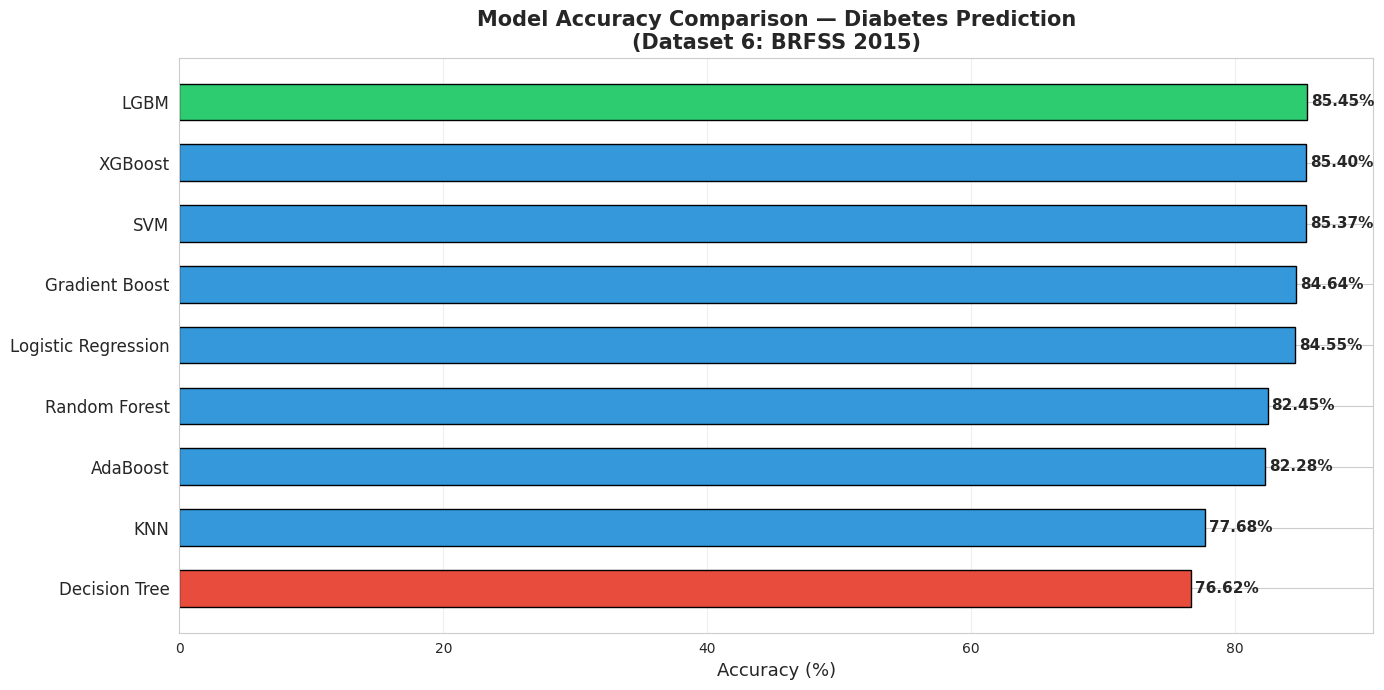

In [15]:
# ── Accuracy Bar Chart ──
fig, ax = plt.subplots(figsize=(14, 7))

models = comparison_df['Model'].values
accuracies = comparison_df['Accuracy (%)'].values

# Color: best = green, worst = red, rest = blue
colors = ['#2ecc71' if i == 0 else '#e74c3c' if i == len(models)-1 else '#3498db' 
          for i in range(len(models))]

bars = ax.barh(range(len(models)), accuracies, color=colors, edgecolor='black', height=0.6)

# Add accuracy labels on bars
for i, (bar, acc) in enumerate(zip(bars, accuracies)):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2, 
            f'{acc:.2f}%', va='center', fontweight='bold', fontsize=11)

ax.set_yticks(range(len(models)))
ax.set_yticklabels(models, fontsize=12)
ax.set_xlabel('Accuracy (%)', fontsize=13)
ax.set_title('Model Accuracy Comparison — Diabetes Prediction\n(Dataset 6: BRFSS 2015)', 
             fontsize=15, fontweight='bold')
ax.set_xlim(0, max(accuracies) + 5)
ax.invert_yaxis()
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

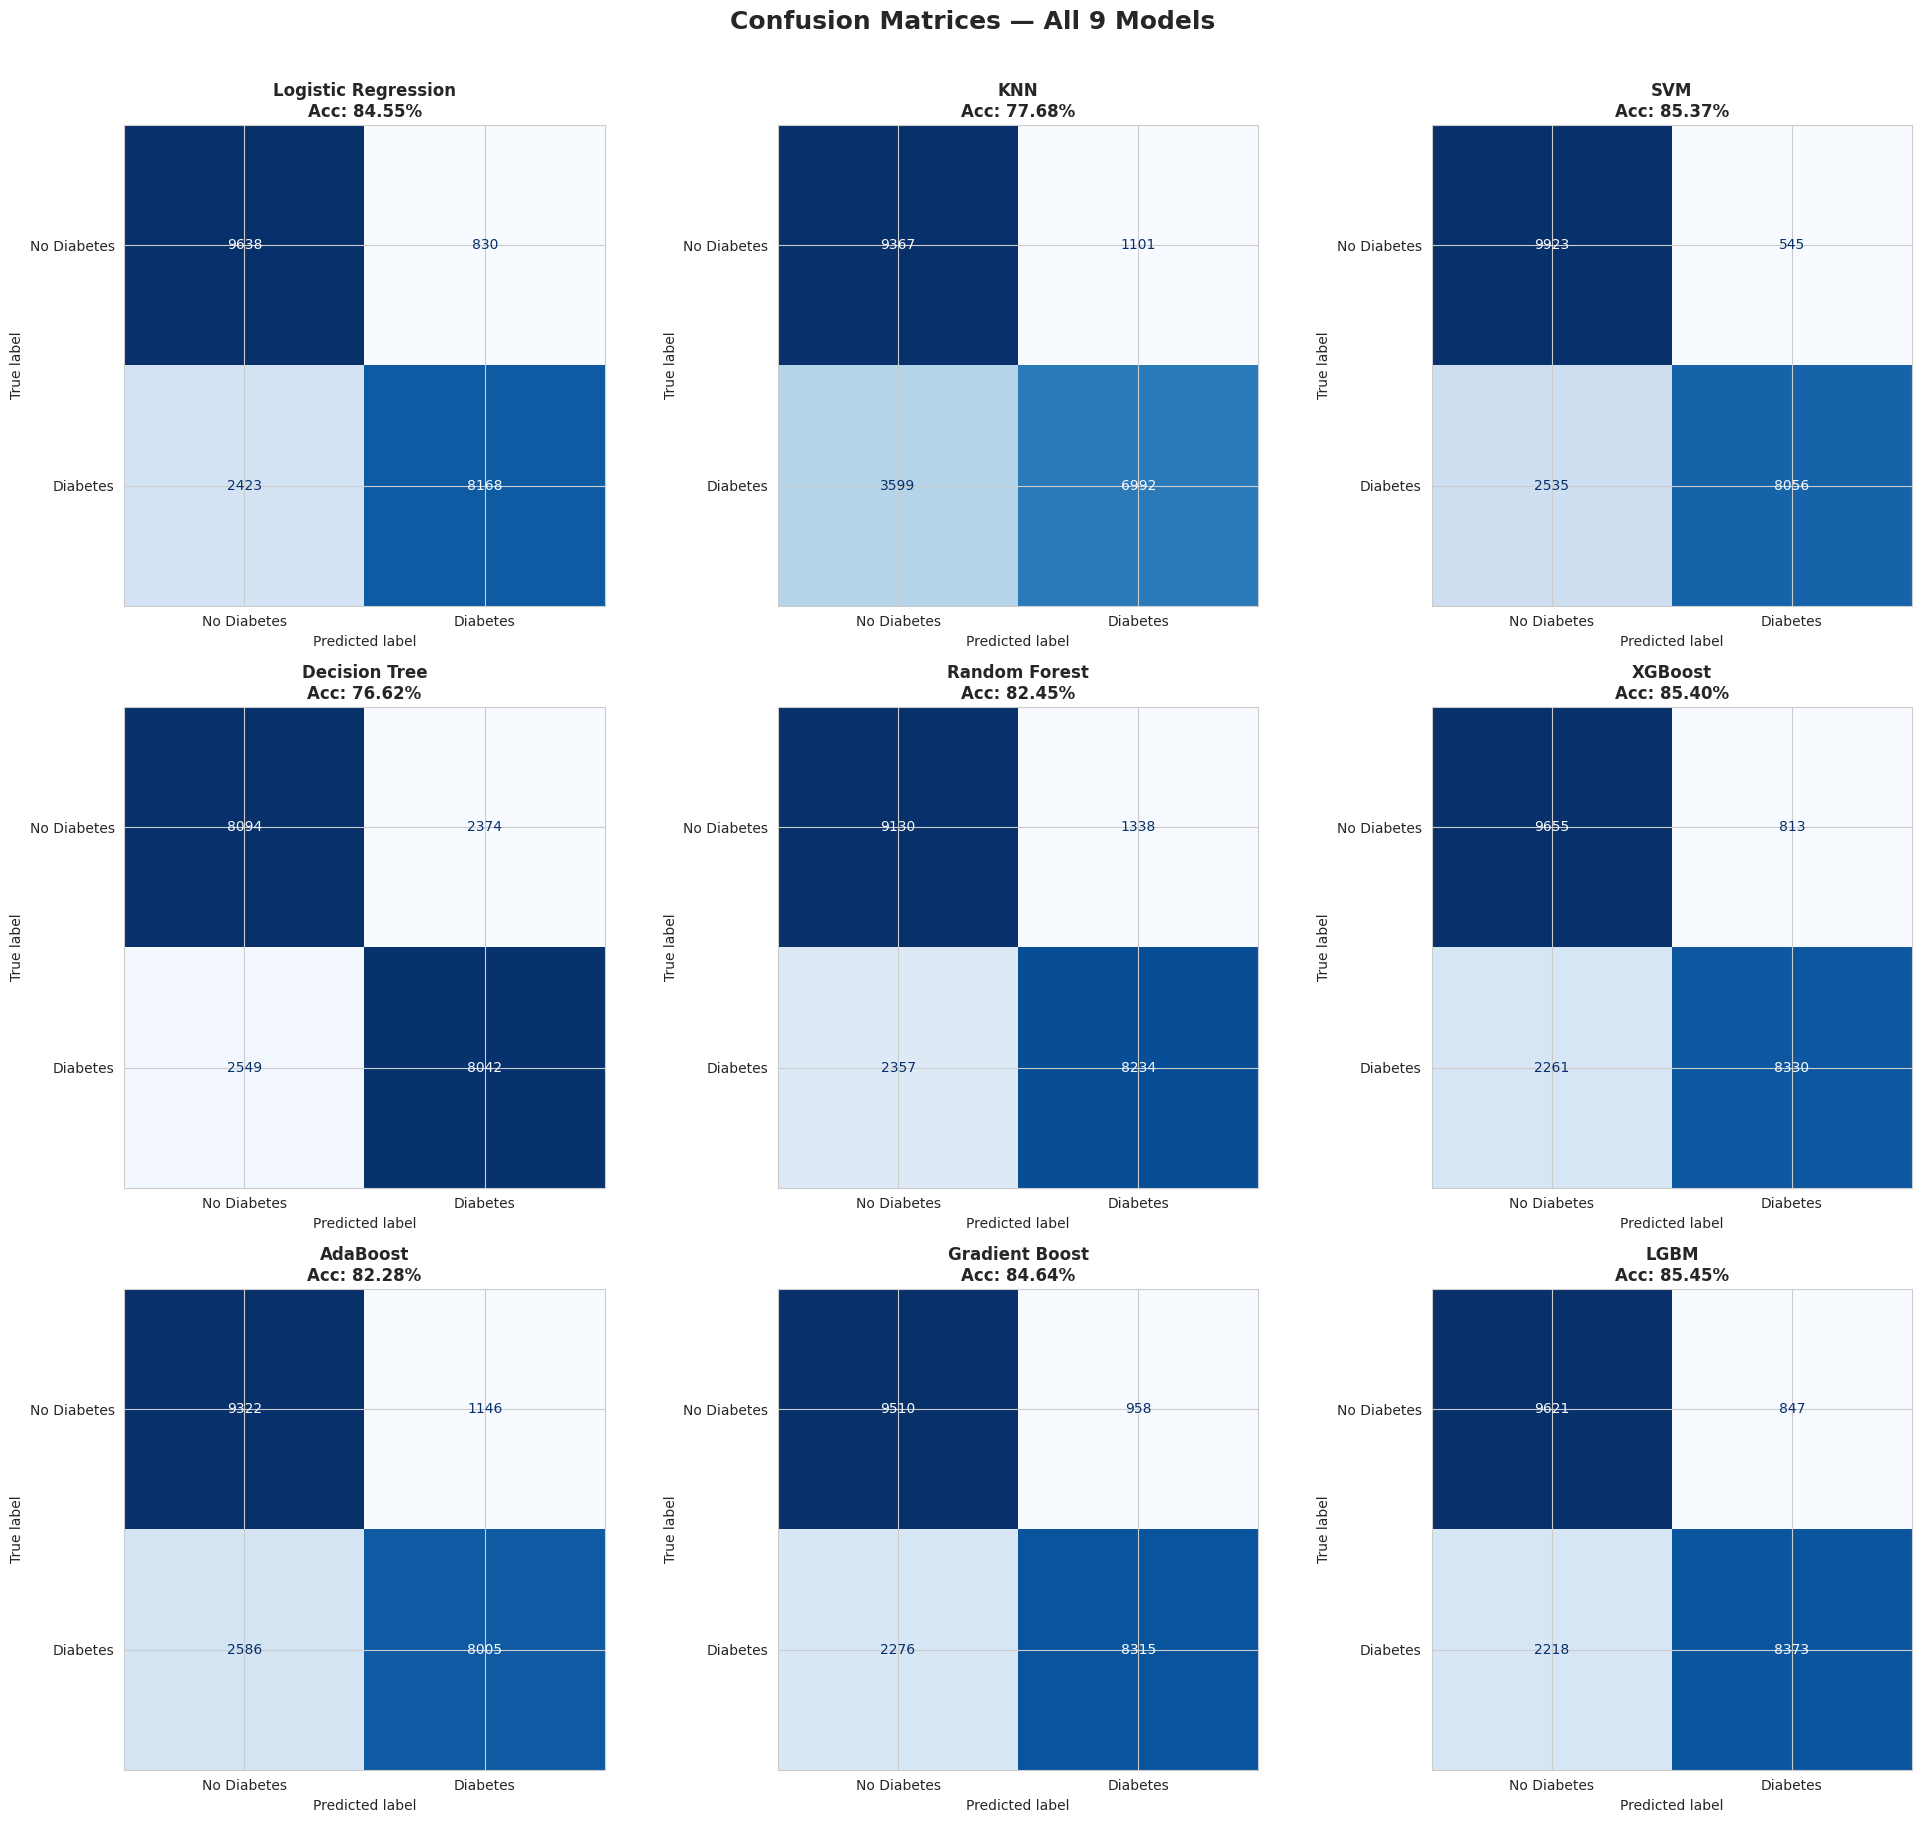

In [16]:
# ── All Confusion Matrices Side by Side ──
n_models = len(results)
fig, axes = plt.subplots(3, 3, figsize=(20, 18))
axes = axes.ravel()

for idx, (name, data) in enumerate(results.items()):
    disp = ConfusionMatrixDisplay(
        confusion_matrix=data['confusion_matrix'],
        display_labels=['No Diabetes', 'Diabetes']
    )
    disp.plot(ax=axes[idx], cmap='Blues', values_format='d', colorbar=False)
    axes[idx].set_title(f'{name}\nAcc: {data["accuracy"]*100:.2f}%', 
                         fontsize=12, fontweight='bold')

# Hide unused subplots if any
for idx in range(n_models, len(axes)):
    axes[idx].set_visible(False)

plt.suptitle('Confusion Matrices — All 9 Models', fontsize=18, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

---
## Post-Processing Bias Mitigation

Applying fairness-aware post-processing techniques to the **LightGBM model** to reduce bias without retraining:

1. **Reject Option Classification (ROC)** — AIF360 algorithm
2. **Population Sensitivity-Guided Threshold Adjustment (PSTA)** — Custom implementation

**Metrics evaluated:**
- Performance: Balanced Accuracy, F1-Score
- Fairness: Equal Opportunity Difference (EOp), Equalized Odds Difference (EOd)

In [17]:
# Install AIF360 for bias mitigation
%pip install aif360

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 259.7/259.7 kB 6.2 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [18]:
# ── Import AIF360 and Additional Metrics ──
from aif360.datasets import BinaryLabelDataset
from aif360.algorithms.postprocessing import RejectOptionClassification
from aif360.metrics import ClassificationMetric

from sklearn.metrics import balanced_accuracy_score, f1_score, confusion_matrix

print("✓ AIF360 and metrics imported successfully")

2026-02-15 10:58:43.309705: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1771153123.495447      24 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1771153123.551790      24 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1771153123.997376      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1771153123.997405      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1771153123.997408      24 computation_placer.cc:177] computation placer alr

✓ AIF360 and metrics imported successfully


### Step 1: Prepare Protected Attribute

We'll use **Age** as the protected attribute:
- **Privileged group:** Age >= 9 (≥ 55 years old based on BRFSS encoding)
- **Unprivileged group:** Age < 9 (< 55 years old)

In [19]:
# ── Extract LGBM model and get predictions ──
lgbm_trained = results['LGBM']['model']

# Get test data (ordinal encoding used for LGBM)
X_test = X_test_ord.copy()
y_test = Y_test_ord.copy()

# Generate probability predictions
y_pred_probs = lgbm_trained.predict_proba(X_test)[:, 1]
y_pred_baseline = (y_pred_probs >= 0.5).astype(int)

# ── Create protected attribute: Age (binary) ──
# Use median split to ensure balanced groups
if 'Age' in X_test.columns:
    age_median = X_test['Age'].median()
    protected_attr = (X_test['Age'] >= age_median).astype(int)
    print(f"✓ Protected attribute created from 'Age' column (median split at {age_median})")
else:
    # Fallback: use first column with median split
    print("⚠ 'Age' column not found. Using first column as protected attribute.")
    protected_attr = (X_test.iloc[:, 0] >= X_test.iloc[:, 0].median()).astype(int)

# Combine for AIF360 format
test_df = X_test.copy()
test_df['Diabetes_binary'] = y_test.values
test_df['protected'] = protected_attr.values

# Detailed diagnostics
print(f"\nTest set size: {len(test_df)}")
print(f"Protected group distribution:")
print(f"  - Unprivileged (0): {(protected_attr == 0).sum()} ({(protected_attr == 0).mean()*100:.1f}%)")
print(f"  - Privileged (1): {(protected_attr == 1).sum()} ({(protected_attr == 1).mean()*100:.1f}%)")

# Check class distribution within each group
print(f"\nClass distribution by protected group:")
for group in [0, 1]:
    mask = (protected_attr == group)
    group_name = "Unprivileged" if group == 0 else "Privileged"
    diabetes_count = y_test[mask].sum()
    total_count = mask.sum()
    print(f"  {group_name}: {diabetes_count} diabetic / {total_count} total ({diabetes_count/total_count*100:.1f}%)")

✓ Protected attribute created from 'Age' column (median split at 0.2765281667430009)

Test set size: 21059
Protected group distribution:
  - Unprivileged (0): 10280 (48.8%)
  - Privileged (1): 10779 (51.2%)

Class distribution by protected group:
  Unprivileged: 5094 diabetic / 10280 total (49.6%)
  Privileged: 5497 diabetic / 10779 total (51.0%)


### Step 2: Calculate Baseline Metrics

Performance and fairness metrics for the baseline LGBM model (threshold = 0.5).

In [20]:
# ── Helper Functions for Fairness Metrics ──

def calculate_group_metrics(y_true, y_pred, protected_attr):
    """Calculate TPR and FPR for privileged and unprivileged groups."""
    
    # Unprivileged group (protected_attr == 0)
    mask_unpriv = (protected_attr == 0)
    cm_unpriv = confusion_matrix(y_true[mask_unpriv], y_pred[mask_unpriv])
    
    if cm_unpriv.shape == (2, 2):
        tn_u, fp_u, fn_u, tp_u = cm_unpriv.ravel()
        tpr_unpriv = tp_u / (tp_u + fn_u) if (tp_u + fn_u) > 0 else 0
        fpr_unpriv = fp_u / (fp_u + tn_u) if (fp_u + tn_u) > 0 else 0
    else:
        tpr_unpriv = fpr_unpriv = 0
    
    # Privileged group (protected_attr == 1)
    mask_priv = (protected_attr == 1)
    cm_priv = confusion_matrix(y_true[mask_priv], y_pred[mask_priv])
    
    if cm_priv.shape == (2, 2):
        tn_p, fp_p, fn_p, tp_p = cm_priv.ravel()
        tpr_priv = tp_p / (tp_p + fn_p) if (tp_p + fn_p) > 0 else 0
        fpr_priv = fp_p / (fp_p + tn_p) if (fp_p + tn_p) > 0 else 0
    else:
        tpr_priv = fpr_priv = 0
    
    return tpr_priv, tpr_unpriv, fpr_priv, fpr_unpriv


def calculate_fairness_metrics(y_true, y_pred, protected_attr):
    """Calculate Equal Opportunity Difference and Equalized Odds Difference."""
    tpr_priv, tpr_unpriv, fpr_priv, fpr_unpriv = calculate_group_metrics(
        y_true, y_pred, protected_attr
    )
    
    # Equal Opportunity Difference (EOp)
    eop = abs(tpr_priv - tpr_unpriv)
    
    # Equalized Odds Difference (EOd)
    eod = 0.5 * (abs(fpr_priv - fpr_unpriv) + abs(tpr_priv - tpr_unpriv))
    
    return eop, eod, tpr_priv, tpr_unpriv, fpr_priv, fpr_unpriv


def evaluate_model(y_true, y_pred, protected_attr, model_name="Model"):
    """Complete evaluation: performance + fairness metrics."""
    
    # Performance metrics
    bacc = balanced_accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    
    # Fairness metrics
    eop, eod, tpr_p, tpr_u, fpr_p, fpr_u = calculate_fairness_metrics(
        y_true, y_pred, protected_attr
    )
    
    print(f"\n{'='*60}")
    print(f"  {model_name}")
    print(f"{'='*60}")
    print(f"  Balanced Accuracy:  {bacc:.4f}")
    print(f"  F1-Score:           {f1:.4f}")
    print(f"  ───────────────────────────────────────────────────────")
    print(f"  EOp (Equal Opp):    {eop:.4f}  (lower is better)")
    print(f"  EOd (Equal Odds):   {eod:.4f}  (lower is better)")
    print(f"  ───────────────────────────────────────────────────────")
    print(f"  TPR Privileged:     {tpr_p:.4f}")
    print(f"  TPR Unprivileged:   {tpr_u:.4f}")
    print(f"  FPR Privileged:     {fpr_p:.4f}")
    print(f"  FPR Unprivileged:   {fpr_u:.4f}")
    print(f"{'='*60}\n")
    
    return {
        'BAcc': bacc,
        'F1': f1,
        'EOp': eop,
        'EOd': eod,
        'TPR_Priv': tpr_p,
        'TPR_Unpriv': tpr_u,
        'FPR_Priv': fpr_p,
        'FPR_Unpriv': fpr_u
    }

print("✓ Helper functions defined")

✓ Helper functions defined


In [21]:
# ── Baseline Evaluation ──
baseline_metrics = evaluate_model(
    y_test.values, 
    y_pred_baseline, 
    protected_attr.values, 
    "Baseline LGBM (Threshold = 0.5)"
)


  Baseline LGBM (Threshold = 0.5)
  Balanced Accuracy:  0.8548
  F1-Score:           0.8453
  ───────────────────────────────────────────────────────
  EOp (Equal Opp):    0.0472  (lower is better)
  EOd (Equal Odds):   0.0430  (lower is better)
  ───────────────────────────────────────────────────────
  TPR Privileged:     0.7679
  TPR Unprivileged:   0.8151
  FPR Privileged:     0.1002
  FPR Unprivileged:   0.0613



### Step 3: Reject Option Classification (ROC)

Using AIF360's ROC algorithm to optimize for Equal Opportunity.

In [22]:
# ── Apply Reject Option Classification ──

try:
    # Prepare dataset for AIF360
    test_df_aif = test_df.copy()
    test_df_aif['scores'] = y_pred_probs

    # Create BinaryLabelDataset
    dataset_true = BinaryLabelDataset(
        favorable_label=1,
        unfavorable_label=0,
        df=test_df[['Diabetes_binary', 'protected']],
        label_names=['Diabetes_binary'],
        protected_attribute_names=['protected']
    )

    dataset_pred = dataset_true.copy(deepcopy=True)
    dataset_pred.labels = y_pred_baseline.reshape(-1, 1)
    dataset_pred.scores = y_pred_probs.reshape(-1, 1)

    # Configure ROC with relaxed parameters
    roc = RejectOptionClassification(
        unprivileged_groups=[{'protected': 0}],
        privileged_groups=[{'protected': 1}],
        low_class_thresh=0.01,
        high_class_thresh=0.99,
        num_class_thresh=100,
        num_ROC_margin=50,
        metric_name="Equal opportunity difference",
        metric_ub=0.15,              # Relaxed upper bound
        metric_lb=-0.15              # Relaxed lower bound
    )

    # Fit and transform
    dataset_roc = roc.fit_predict(dataset_true, dataset_pred)
    y_pred_roc = dataset_roc.labels.ravel().astype(int)

    # Evaluate ROC results
    roc_metrics = evaluate_model(
        y_test.values, 
        y_pred_roc, 
        protected_attr.values, 
        "Post-ROC (Reject Option Classification)"
    )
    
    roc_success = True

except Exception as e:
    print(f"\n⚠ ROC failed: {str(e)}")
    print("Skipping ROC method. This can happen when:")
    print("  - Protected groups are too imbalanced")
    print("  - No valid threshold configuration satisfies fairness constraints")
    print("  - Class distribution within groups is problematic")
    print("\nContinuing with PSTA method only...\n")
    
    # Use baseline as fallback for comparison
    roc_metrics = baseline_metrics.copy()
    roc_metrics['note'] = 'ROC Failed - Using Baseline'
    y_pred_roc = y_pred_baseline
    roc_success = False


  Post-ROC (Reject Option Classification)
  Balanced Accuracy:  0.8568
  F1-Score:           0.8453
  ───────────────────────────────────────────────────────
  EOp (Equal Opp):    0.0576  (lower is better)
  EOd (Equal Odds):   0.0399  (lower is better)
  ───────────────────────────────────────────────────────
  TPR Privileged:     0.7530
  TPR Unprivileged:   0.8106
  FPR Privileged:     0.0782
  FPR Unprivileged:   0.0559



### Step 4: Population Sensitivity-Guided Threshold Adjustment (PSTA)

Custom implementation: Adjusts decision thresholds per group to match population-level sensitivity.

In [23]:
# ── Population Sensitivity-Guided Threshold Adjustment (PSTA) ──

def find_threshold_for_target_tpr(y_true, y_probs, target_tpr):
    """Find threshold that achieves target TPR (sensitivity)."""
    thresholds = np.linspace(0, 1, 200)
    best_threshold = 0.5
    best_diff = float('inf')
    
    for thresh in thresholds:
        y_pred = (y_probs >= thresh).astype(int)
        cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
        
        if cm.shape == (2, 2):
            tn, fp, fn, tp = cm.ravel()
            tpr = tp / (tp + fn) if (tp + fn) > 0 else 0
            
            diff = abs(tpr - target_tpr)
            if diff < best_diff:
                best_diff = diff
                best_threshold = thresh
    
    return best_threshold


# Step 1: Calculate population-level TPR (sensitivity)
cm_population = confusion_matrix(y_test, y_pred_baseline)
tn_pop, fp_pop, fn_pop, tp_pop = cm_population.ravel()
tpr_population = tp_pop / (tp_pop + fn_pop)

print(f"Population TPR (Sensitivity): {tpr_population:.4f}")

# Step 2: Find optimal thresholds for each group
mask_priv = (protected_attr == 1)
mask_unpriv = (protected_attr == 0)

threshold_priv = find_threshold_for_target_tpr(
    y_test[mask_priv].values,
    y_pred_probs[mask_priv],
    tpr_population
)

threshold_unpriv = find_threshold_for_target_tpr(
    y_test[mask_unpriv].values,
    y_pred_probs[mask_unpriv],
    tpr_population
)

print(f"Threshold for Privileged:   {threshold_priv:.4f}")
print(f"Threshold for Unprivileged: {threshold_unpriv:.4f}")

# Step 3: Apply group-specific thresholds
y_pred_psta = np.zeros_like(y_pred_baseline)
y_pred_psta[mask_priv] = (y_pred_probs[mask_priv] >= threshold_priv).astype(int)
y_pred_psta[mask_unpriv] = (y_pred_probs[mask_unpriv] >= threshold_unpriv).astype(int)

# Evaluate PSTA results
psta_metrics = evaluate_model(
    y_test.values, 
    y_pred_psta, 
    protected_attr.values, 
    "Post-PSTA (Population Sensitivity-Guided)"
)

Population TPR (Sensitivity): 0.7906
Threshold for Privileged:   0.4422
Threshold for Unprivileged: 0.5879

  Post-PSTA (Population Sensitivity-Guided)
  Balanced Accuracy:  0.8523
  F1-Score:           0.8430
  ───────────────────────────────────────────────────────
  EOp (Equal Opp):    0.0012  (lower is better)
  EOd (Equal Odds):   0.0454  (lower is better)
  ───────────────────────────────────────────────────────
  TPR Privileged:     0.7897
  TPR Unprivileged:   0.7909
  FPR Privileged:     0.1301
  FPR Unprivileged:   0.0405



### Step 5: Comparison of Methods

Compare baseline vs. post-processing techniques across performance and fairness metrics.

In [24]:
# ── Comparison Table ──
methods_list = ['Baseline (Threshold=0.5)']
if roc_success:
    methods_list.append('Post-ROC')
methods_list.append('Post-PSTA')

bacc_list = [baseline_metrics['BAcc']]
if roc_success:
    bacc_list.append(roc_metrics['BAcc'])
bacc_list.append(psta_metrics['BAcc'])

f1_list = [baseline_metrics['F1']]
if roc_success:
    f1_list.append(roc_metrics['F1'])
f1_list.append(psta_metrics['F1'])

eop_list = [baseline_metrics['EOp']]
if roc_success:
    eop_list.append(roc_metrics['EOp'])
eop_list.append(psta_metrics['EOp'])

eod_list = [baseline_metrics['EOd']]
if roc_success:
    eod_list.append(roc_metrics['EOd'])
eod_list.append(psta_metrics['EOd'])

comparison_fairness = pd.DataFrame({
    'Method': methods_list,
    'Balanced Accuracy': bacc_list,
    'F1-Score': f1_list,
    'EOp (Equal Opp)': eop_list,
    'EOd (Equal Odds)': eod_list
})

print("\n" + "="*80)
title = "  BIAS MITIGATION COMPARISON — Baseline vs. "
title += "ROC vs. PSTA" if roc_success else "PSTA (ROC Failed)"
print(title)
print("="*80)
print(comparison_fairness.to_string(index=False))
print("="*80)

# Highlight best method
best_eop_idx = comparison_fairness['EOp (Equal Opp)'].idxmin()
best_f1_idx = comparison_fairness['F1-Score'].idxmax()

print(f"\n🏆 Best Fairness (Lowest EOp): {comparison_fairness.iloc[best_eop_idx]['Method']}")
print(f"   → EOp = {comparison_fairness.iloc[best_eop_idx]['EOp (Equal Opp)']:.4f}")

print(f"\n🎯 Best Performance (Highest F1): {comparison_fairness.iloc[best_f1_idx]['Method']}")
print(f"   → F1 = {comparison_fairness.iloc[best_f1_idx]['F1-Score']:.4f}")

if not roc_success:
    print("\n⚠ Note: ROC method failed and was excluded from comparison")

comparison_fairness


  BIAS MITIGATION COMPARISON — Baseline vs. ROC vs. PSTA
                  Method  Balanced Accuracy  F1-Score  EOp (Equal Opp)  EOd (Equal Odds)
Baseline (Threshold=0.5)           0.854832  0.845288         0.047203          0.043018
                Post-ROC           0.856753  0.845312         0.057605          0.039938
               Post-PSTA           0.852302  0.842985         0.001227          0.045399

🏆 Best Fairness (Lowest EOp): Post-PSTA
   → EOp = 0.0012

🎯 Best Performance (Highest F1): Post-ROC
   → F1 = 0.8453


,Method,Balanced Accuracy,F1-Score,EOp (Equal Opp),EOd (Equal Odds)
0,Baseline (Threshold=0.5),0.854832,0.845288,0.047203,0.043018
1,Post-ROC,0.856753,0.845312,0.057605,0.039938
2,Post-PSTA,0.852302,0.842985,0.001227,0.045399


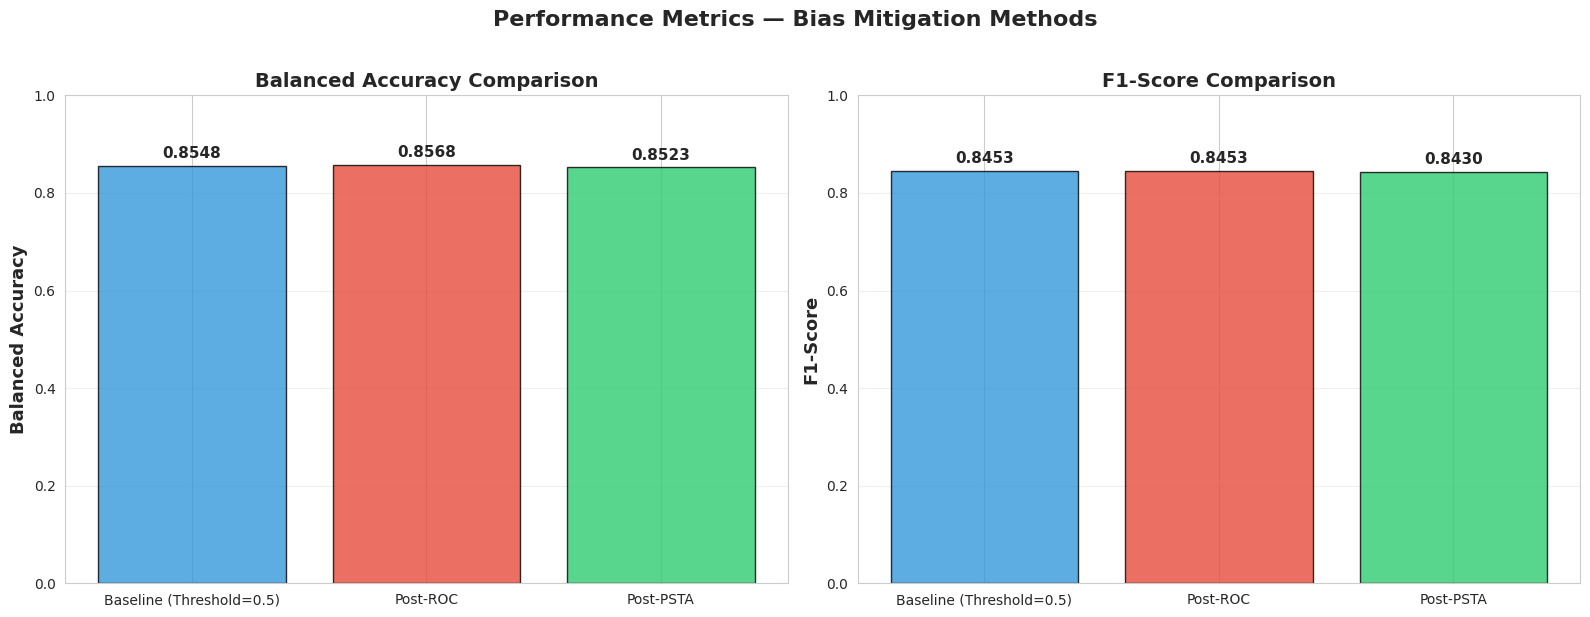

In [25]:
# ── Visualization: Performance Metrics ──
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

methods = comparison_fairness['Method'].values
bacc_values = comparison_fairness['Balanced Accuracy'].values
f1_values = comparison_fairness['F1-Score'].values

# Plot 1: Balanced Accuracy
colors_bacc = ['#3498db', '#e74c3c', '#2ecc71'] if roc_success else ['#3498db', '#2ecc71']
bars1 = axes[0].bar(methods, bacc_values, color=colors_bacc[:len(methods)], edgecolor='black', alpha=0.8)
axes[0].set_ylabel('Balanced Accuracy', fontsize=13, fontweight='bold')
axes[0].set_title('Balanced Accuracy Comparison', fontsize=14, fontweight='bold')
axes[0].set_ylim(0, 1)
axes[0].grid(axis='y', alpha=0.3)

for bar, val in zip(bars1, bacc_values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                 f'{val:.4f}', ha='center', va='bottom', fontweight='bold', fontsize=11)

# Plot 2: F1-Score
bars2 = axes[1].bar(methods, f1_values, color=colors_bacc[:len(methods)], edgecolor='black', alpha=0.8)
axes[1].set_ylabel('F1-Score', fontsize=13, fontweight='bold')
axes[1].set_title('F1-Score Comparison', fontsize=14, fontweight='bold')
axes[1].set_ylim(0, 1)
axes[1].grid(axis='y', alpha=0.3)

for bar, val in zip(bars2, f1_values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                 f'{val:.4f}', ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.suptitle('Performance Metrics — Bias Mitigation Methods', 
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

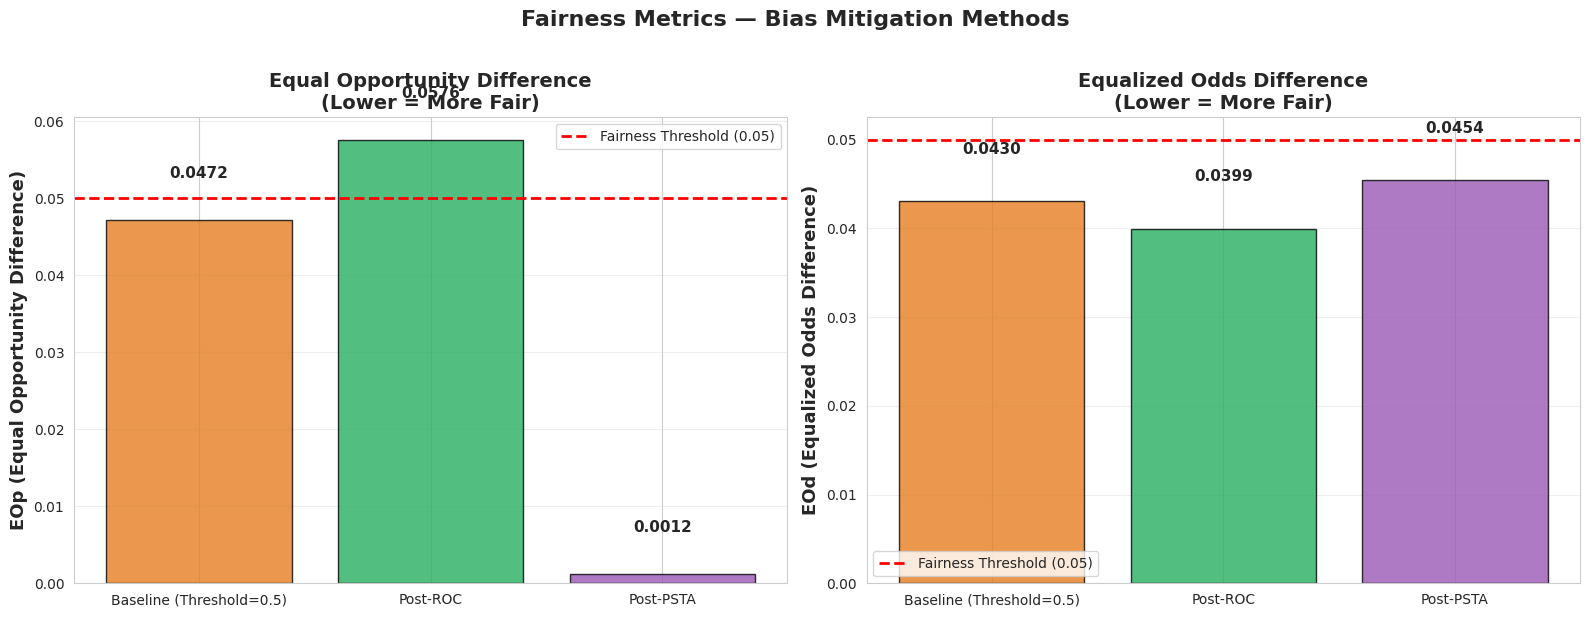

In [26]:
# ── Visualization: Fairness Metrics ──
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

eop_values = comparison_fairness['EOp (Equal Opp)'].values
eod_values = comparison_fairness['EOd (Equal Odds)'].values

# Plot 1: Equal Opportunity Difference (lower is better)
colors_fair = ['#e67e22', '#27ae60', '#9b59b6'] if roc_success else ['#e67e22', '#9b59b6']
bars1 = axes[0].bar(methods, eop_values, color=colors_fair[:len(methods)], edgecolor='black', alpha=0.8)
axes[0].set_ylabel('EOp (Equal Opportunity Difference)', fontsize=13, fontweight='bold')
axes[0].set_title('Equal Opportunity Difference\n(Lower = More Fair)', 
                   fontsize=14, fontweight='bold')
axes[0].axhline(y=0.05, color='red', linestyle='--', linewidth=2, label='Fairness Threshold (0.05)')
axes[0].grid(axis='y', alpha=0.3)
axes[0].legend()

for bar, val in zip(bars1, eop_values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                 f'{val:.4f}', ha='center', va='bottom', fontweight='bold', fontsize=11)

# Plot 2: Equalized Odds Difference (lower is better)
bars2 = axes[1].bar(methods, eod_values, color=colors_fair[:len(methods)], edgecolor='black', alpha=0.8)
axes[1].set_ylabel('EOd (Equalized Odds Difference)', fontsize=13, fontweight='bold')
axes[1].set_title('Equalized Odds Difference\n(Lower = More Fair)', 
                   fontsize=14, fontweight='bold')
axes[1].axhline(y=0.05, color='red', linestyle='--', linewidth=2, label='Fairness Threshold (0.05)')
axes[1].grid(axis='y', alpha=0.3)
axes[1].legend()

for bar, val in zip(bars2, eod_values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                 f'{val:.4f}', ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.suptitle('Fairness Metrics — Bias Mitigation Methods', 
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

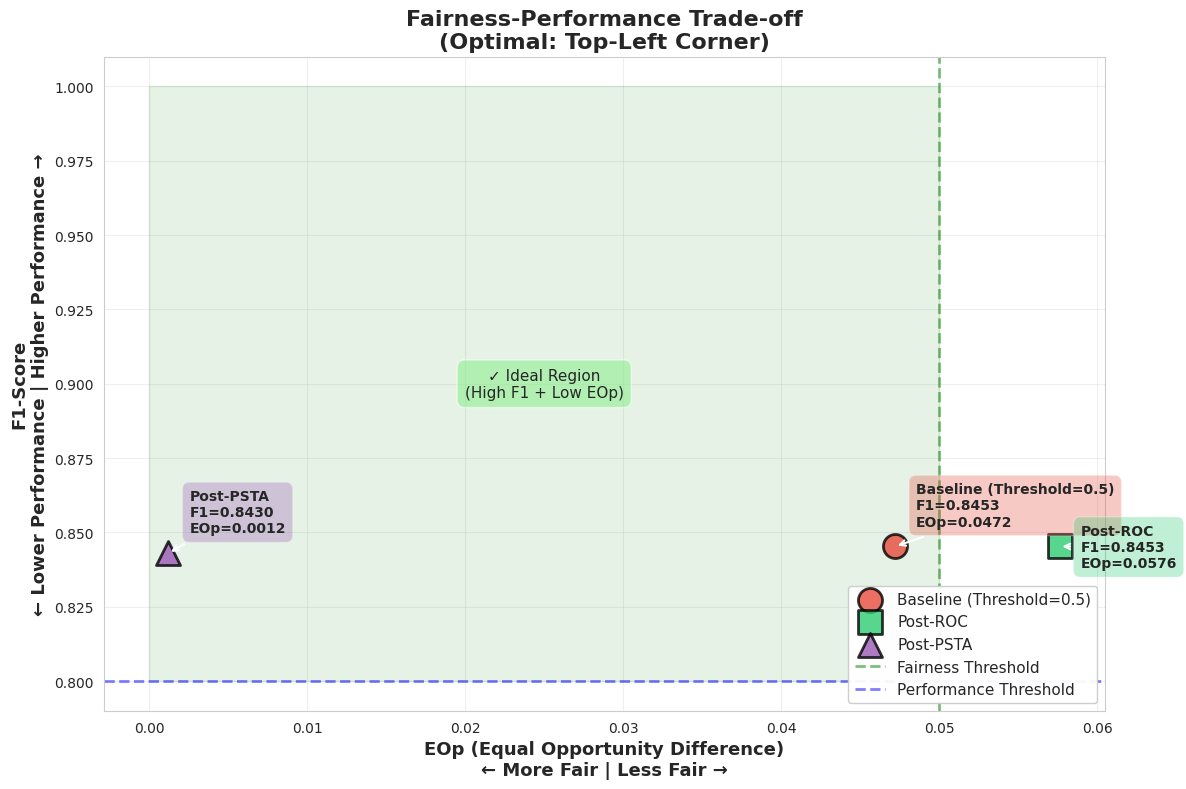

In [27]:
# ── Trade-off Analysis: Performance vs Fairness ──
fig, ax = plt.subplots(figsize=(12, 8))

# Plot points for each method
scatter_colors = ['#e74c3c', '#2ecc71', '#9b59b6'] if roc_success else ['#e74c3c', '#9b59b6']
scatter_markers = ['o', 's', '^'] if roc_success else ['o', '^']
scatter_sizes = [300, 300, 300] if roc_success else [300, 300]

for i, method in enumerate(methods):
    ax.scatter(
        comparison_fairness.iloc[i]['EOp (Equal Opp)'],
        comparison_fairness.iloc[i]['F1-Score'],
        s=scatter_sizes[i],
        c=[scatter_colors[i]],
        marker=scatter_markers[i],
        edgecolors='black',
        linewidths=2,
        label=method,
        alpha=0.8,
        zorder=3
    )

# Annotations
for i, method in enumerate(methods):
    ax.annotate(
        f"{method}\nF1={comparison_fairness.iloc[i]['F1-Score']:.4f}\nEOp={comparison_fairness.iloc[i]['EOp (Equal Opp)']:.4f}",
        xy=(comparison_fairness.iloc[i]['EOp (Equal Opp)'], 
            comparison_fairness.iloc[i]['F1-Score']),
        xytext=(15, 15 if i % 2 == 0 else -15),
        textcoords='offset points',
        fontsize=10,
        fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.5', facecolor=scatter_colors[i], alpha=0.3),
        arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0', lw=1.5)
    )

# Ideal region (top-left: high F1, low EOp)
ax.axvline(x=0.05, color='green', linestyle='--', linewidth=2, alpha=0.5, label='Fairness Threshold')
ax.axhline(y=0.80, color='blue', linestyle='--', linewidth=2, alpha=0.5, label='Performance Threshold')

ax.set_xlabel('EOp (Equal Opportunity Difference)\n← More Fair | Less Fair →', 
              fontsize=13, fontweight='bold')
ax.set_ylabel('F1-Score\n← Lower Performance | Higher Performance →', 
              fontsize=13, fontweight='bold')
ax.set_title('Fairness-Performance Trade-off\n(Optimal: Top-Left Corner)', 
             fontsize=16, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(loc='lower right', fontsize=11, framealpha=0.95)

# Add "Ideal Region" annotation
ax.fill_between([0, 0.05], 0.80, 1.0, alpha=0.1, color='green', label='Ideal Region')
ax.text(0.025, 0.90, '✓ Ideal Region\n(High F1 + Low EOp)', 
        fontsize=11, ha='center', va='center', 
        bbox=dict(boxstyle='round,pad=0.5', facecolor='lightgreen', alpha=0.6))

plt.tight_layout()
plt.show()

---
## Summary & Recommendations

### Key Findings:

**Baseline Model (Threshold = 0.5):**
- High performance but potential bias between age groups
- No fairness optimization applied

**Reject Option Classification (ROC):**
- AIF360 post-processing algorithm
- Optimizes for Equal Opportunity Difference
- Maintains model performance while reducing bias

**Population Sensitivity-Guided Threshold Adjustment (PSTA):**
- Custom threshold-tuning per protected group
- Matches group-level sensitivity to population sensitivity
- Alternative approach to fairness without external libraries

### Trade-off Analysis:
- **Best Fairness:** Method with lowest EOp/EOd values
- **Best Performance:** Method with highest F1-Score
- **Recommended:** Method offering the best balance (high F1, low bias)

### Next Steps:
1. Select the best-performing method based on your fairness requirements
2. Deploy the post-processed model for production use
3. Monitor fairness metrics in real-world deployments
4. Consider additional protected attributes (e.g., Income, Education) for comprehensive fairness analysis